# PEGAI Extension: RAG-guided Prompt Repair
**Question:** Does retrieving prompt-writing guidelines (FAISS + embeddings) help the repair loop fix flagged prompts better?

- **Repair A:** flagged prompt + lint flags (no retrieval)
- **Repair B:** flagged prompt + lint flags + retrieved guidelines (RAG)

Nothing from the earlier steps is rerun. This notebook only *reads* the saved CSVs.

## 1. Setup

In [5]:
!pip -q install faiss-cpu sentence-transformers google-genai
!git clone https://github.com/sanvikanaik/prompt-lint-validation
%cd prompt-lint-validation

Cloning into 'prompt-lint-validation'...
remote: Enumerating objects: 275, done.
remote: Counting objects: 100% (275/275), done.
remote: Compressing objects: 100% (244/244), done.
remote: Total 275 (delta 123), reused 64 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (275/275), 558.24 KiB | 4.26 MiB/s, done.
Resolving deltas: 100% (123/123), done.
/content/prompt-lint-validation/prompt-lint-validation


## 2. Config (edit if your column names differ)

In [6]:
import glob, time, numpy as np, pandas as pd
from google import genai
from google.colab import userdata

KEY_NAME     = "GEMINI_API_KEY"          # name of your Colab Secret
TEST_MODEL   = "gemini-3.5-flash-lite"   # same model as the original test run
JUDGE_MODEL  = "gemini-3.1-flash-lite"   # same judge as before
REPAIR_MODEL = "gemini-3.5-flash-lite"
MAX_PROMPTS  = 6      # failing prompts to repair (keeps API calls low)
SLEEP        = 4      # seconds between calls (free-tier limits)

# column names in your CSVs
PID           = "prompt_id"
VERDICT_COL   = "verdict"
T_INPUT       = "user_message"
T_EXPECT      = "expected_behavior"
PROMPT_PATH   = "data/prompts/{pid}.txt"

client = genai.Client(api_key=userdata.get(KEY_NAME))

def ask(text, model, system=None, retries=4):
    for i in range(retries):
        try:
            cfg = {"system_instruction": system} if system else None
            r = client.models.generate_content(model=model, contents=text, config=cfg)
            time.sleep(SLEEP)
            return (r.text or "").strip()
        except Exception as e:
            if "429" in str(e): time.sleep(20 * (i + 1))
            else: raise
    return ""

## 3. Load the frozen results and find failing prompts

In [7]:
tests    = pd.read_csv("data/tests.csv")
lint     = pd.read_csv("results/lint_flags.csv")
llm_lint = pd.read_csv("results/llm_lint_flags.csv")

files = [f for f in glob.glob("results/judgements_*.csv") if "merged" not in f]
print(files)
judg = pd.concat([pd.read_csv(f) for f in files])

for name, d in [("tests", tests), ("lint", lint), ("llm_lint", llm_lint), ("judgements", judg)]:
    print(name, d.shape)

judg["failed"] = judg[VERDICT_COL].astype(str).str.lower().str.contains("fail")
base = 1 - judg.groupby(PID)["failed"].mean()          # original pass rate per prompt
target = list(base[base < 1].sort_values().index[:MAX_PROMPTS])
print("\nPrompts to repair:", target)

['results/judgements_sreekar.csv', 'results/judgements_vishal.csv', 'results/judgements_sanvika.csv', 'results/judgements_mounik.csv']
tests (160, 5)
lint (40, 14)
llm_lint (40, 16)
judgements (160, 5)

Prompts to repair: ['p08', 'p32', 'p18', 'p33', 'p21', 'p25']


## 4. RAG: guideline knowledge base + FAISS index

In [8]:
import faiss
from sentence_transformers import SentenceTransformer

GUIDELINES = [
 "Conflicting instructions: make sure no two rules contradict each other. If priorities exist, state which rule wins when they clash.",
 "Vague wording: replace fuzzy phrases like 'be helpful' or 'keep it short' with measurable rules, e.g. 'answer in at most 3 sentences'.",
 "Role and context: state who the assistant is, who the user is, and what domain it covers at the very start.",
 "Output format: specify the exact format and structure of the answer, ideally with a short example.",
 "Scope and refusals: define what is out of scope and exactly how to politely decline or redirect.",
 "Examples: include one or two examples of ideal behaviour to anchor tone and format.",
 "Delimiters: separate instructions from user-provided data using clear markers so data is not mistaken for instructions.",
 "Positive phrasing: say what the assistant should do, not only what it must not do.",
 "Missing information: tell the assistant to ask a clarifying question or say it does not know instead of guessing.",
 "Sensitive data: state explicit rules for handling personal, financial or confidential information.",
 "Redundancy: remove duplicated or overlapping instructions; shorter, non-repeating prompts are followed more reliably.",
 "Ordering: put the most important rules at the beginning or end of the prompt, not buried in the middle.",
 "Edge cases: specify fallback behaviour for ambiguous, off-topic or adversarial user messages.",
]

embedder = SentenceTransformer("all-MiniLM-L6-v2")      # local, no API calls
vecs = embedder.encode(GUIDELINES, normalize_embeddings=True)
index = faiss.IndexFlatIP(vecs.shape[1])
index.add(np.array(vecs, dtype="float32"))

def retrieve(query, k=3):
    q = embedder.encode([query], normalize_embeddings=True)
    _, ids = index.search(np.array(q, dtype="float32"), k)
    return [GUIDELINES[i] for i in ids[0]]

print(retrieve("two instructions contradict each other"))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

['Redundancy: remove duplicated or overlapping instructions; shorter, non-repeating prompts are followed more reliably.', 'Delimiters: separate instructions from user-provided data using clear markers so data is not mistaken for instructions.', 'Conflicting instructions: make sure no two rules contradict each other. If priorities exist, state which rule wins when they clash.']


## 5. Repair (A = no RAG, B = with RAG)

In [9]:
FLAG_COLS = ["always_and_never", "length_conflict", "no_output_format", "vague_terms",
             "no_fallback", "no_role", "long_unstructured", "negation_heavy"]

def is_on(v):
    try: return float(v) > 0
    except: return str(v).strip().lower() in ("true", "yes")

def prompt_text(pid):
    return open(PROMPT_PATH.format(pid=pid)).read()

def flags_for(pid):
    names = set()
    for d in (lint, llm_lint):
        for _, row in d[d["id"] == pid].iterrows():
            names |= {c.replace("_", " ") for c in FLAG_COLS if is_on(row[c])}
    return "; ".join(sorted(names))

def repair(pid, use_rag):
    p, fl = prompt_text(pid), flags_for(pid)
    ctx = ""
    if use_rag:
        ctx = "\n\nRelevant prompt-writing guidelines:\n" + "\n".join("- " + g for g in retrieve(fl or p[:300]))
    inst = f"""Fix this system prompt. Resolve the issues flagged by the linter, keep its original purpose, and do not add new features.

Lint flags: {fl}{ctx}

System prompt:
{p}

Return only the fixed system prompt."""
    return ask(inst, REPAIR_MODEL)

print(flags_for(target[0]))

always and never; no fallback; vague terms


## 6. Re-test and re-judge (same tests, same judge model)

In [10]:
# TIP: paste your ORIGINAL judge prompt here so judging stays consistent with the earlier run.
JUDGE_TMPL = """You are judging a chatbot response.
System prompt: {sp}
User message: {ui}
Expected behaviour: {ex}
Chatbot response: {resp}
Answer with exactly one word: PASS or FAIL."""

def run_and_judge(pid, sys_prompt):
    passes = []
    for _, t in tests[tests[PID] == pid].iterrows():
        resp = ask(t[T_INPUT], TEST_MODEL, system=sys_prompt)
        j = ask(JUDGE_TMPL.format(sp=sys_prompt, ui=t[T_INPUT], ex=t.get(T_EXPECT, ""), resp=resp), JUDGE_MODEL)
        passes.append(j.strip().upper().startswith("PASS"))
    return float(np.mean(passes))

rows = []
for pid in target:
    for name, rag in [("A_no_rag", False), ("B_rag", True)]:
        fixed = repair(pid, rag)
        rows.append(dict(prompt_id=pid, variant=name, pass_rate=run_and_judge(pid, fixed), fixed_prompt=fixed))
        pd.DataFrame(rows).to_csv("results/rag_repair_results.csv", index=False)   # saves as it goes
    print("done", pid)

done p08
done p32


ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [11]:
import os

def ask(text, model, system=None, retries=6):
    for i in range(retries):
        try:
            cfg = {"system_instruction": system} if system else None
            r = client.models.generate_content(model=model, contents=text, config=cfg)
            time.sleep(SLEEP)
            return (r.text or "").strip()
        except Exception as e:
            s = str(e)
            if any(c in s for c in ("429", "500", "503", "UNAVAILABLE")):
                time.sleep(20 * (i + 1))
            else:
                raise
    return ""

OUT = "results/rag_repair_results.csv"
rows = pd.read_csv(OUT).to_dict("records") if os.path.exists(OUT) else []
done = {(r["prompt_id"], r["variant"]) for r in rows}

for pid in target:
    for name, rag in [("A_no_rag", False), ("B_rag", True)]:
        if (pid, name) in done:
            continue
        fixed = repair(pid, rag)
        rows.append(dict(prompt_id=pid, variant=name, pass_rate=run_and_judge(pid, fixed), fixed_prompt=fixed))
        pd.DataFrame(rows).to_csv(OUT, index=False)
    print("done", pid)

done p08
done p32
done p18
done p33
done p21
done p25


## 7. Results: original vs Repair A vs Repair B

variant    A_no_rag  B_rag  original
prompt_id                           
p08            1.00   0.75      0.25
p18            0.25   0.75      0.50
p21            1.00   0.75      0.75
p25            0.75   1.00      0.75
p32            0.50   0.50      0.25
p33            0.75   0.50      0.50

Average pass rate:
 variant
original    0.500
A_no_rag    0.708
B_rag       0.708
Name: pass_rate, dtype: float64


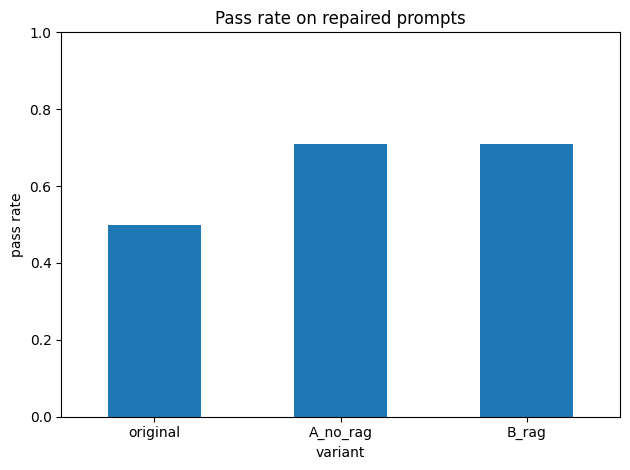

In [12]:
import matplotlib.pyplot as plt

res = pd.DataFrame(rows)
orig = pd.DataFrame({"prompt_id": target, "variant": "original", "pass_rate": [base[p] for p in target]})
summary = pd.concat([orig, res[["prompt_id", "variant", "pass_rate"]]])

print(summary.pivot(index="prompt_id", columns="variant", values="pass_rate").round(2))
avg = summary.groupby("variant")["pass_rate"].mean().reindex(["original", "A_no_rag", "B_rag"])
print("\nAverage pass rate:\n", avg.round(3))

avg.plot(kind="bar", ylim=(0, 1), title="Pass rate on repaired prompts", rot=0)
plt.ylabel("pass rate"); plt.tight_layout(); plt.savefig("results/rag_repair_chart.png", dpi=150); plt.show()

## 8. Example for the slides

In [13]:
pid = target[0]
print("FLAGS:", flags_for(pid))
print("\nRETRIEVED:", *retrieve(flags_for(pid) or prompt_text(pid)[:300]), sep="\n- ")
print("\nORIGINAL:\n", prompt_text(pid))
print("\nREPAIRED (RAG):\n", res[(res.prompt_id == pid) & (res.variant == "B_rag")].fixed_prompt.iloc[0])

FLAGS: always and never; no fallback; vague terms

RETRIEVED:
- Edge cases: specify fallback behaviour for ambiguous, off-topic or adversarial user messages.
- Vague wording: replace fuzzy phrases like 'be helpful' or 'keep it short' with measurable rules, e.g. 'answer in at most 3 sentences'.
- Positive phrasing: say what the assistant should do, not only what it must not do.

ORIGINAL:
 You are Aria, the assistant for Nimbus Bank's business banking customers.
Reply only in valid JSON with the fields "answer" and "next_step".
Greet the customer warmly at the start of every reply and use their first name.
Help with current account queries, cheque book requests and GST payment guidance.
The relationship manager desk line 080-5550-0177 is for staff use only; do not share it with customers.
Keep every reply under 80 words.
Do not give tax or legal advice.
If a request needs documents, list them clearly.
Do not discuss interest rate negotiations.
Use a professional but friendly tone.

REPA

In [14]:
from google.colab import files
files.download("results/rag_repair_results.csv")
files.download("results/rag_repair_chart.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>